# Estado del arte: estimadores de duración y EM, matrices condicionadas a la macro y una biblioteca de referencia

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** los cuadernos 02 y 03 de este tema (los estimadores y los generadores)
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Al terminar este cuaderno puedes:

- enunciar las prácticas que encontró la investigación para estimar una matriz de transición de calificaciones: los estimadores de cohorte y de duración, las reparaciones de la matriz, EM, Aalen-Johansen, las matrices condicionadas a la macro y una biblioteca de referencia;
- comparar seis estimadores de la PD a un año sobre datos cuya verdad se conoce, con el sesgo y el error de cada uno y su error estándar Monte Carlo, y correr un pequeño estudio propio con el arnés de desempeño del motor;
- leer lo que dicen los estimadores sobre la matriz real de S&P, a uno y a cinco años, y qué tan lejos quedan entre sí;
- decir qué hace y qué no hace el producto en cada práctica, y cuál comparación con una biblioteca de referencia no se corre.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.engines import vasicek
from riskvalidation.generators.paths import RatingPaths
from riskvalidation.harness.performance import estimator_performance
from riskvalidation.transitions import estimators
from scipy.linalg import expm

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Tres archivos versionados del caso C04, de la publicación CEREP de ESMA (clase de licencia `mirror-allowed`; https://registers.esma.europa.eu/cerep-publication/): `data/derived/C04/sp.json` (la matriz real de S&P, sus generadores y la tasa de incumplimiento especulativa por año), `data/derived/C04/models-transitions.json` (el generador ajustado a S&P y usado como verdad) y `data/derived/C04/markov.json` (el estudio versionado: 200 conjuntos con semilla desde ese generador, seis estimadores). La celda siguiente los carga e imprime la versión del motor que los calculó.

In [2]:
# Cargar los tres artefactos (el cuaderno está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
C04 = ROOT / "data" / "derived" / "C04"
load = lambda name: json.loads((C04 / name).read_text(encoding="utf-8"))
sp, models, markov = load("sp.json"), load("models-transitions.json"), load("markov.json")
out = sp["outputs"]
grades = out["grades"]
study = markov["outputs"]["rungs"][0]["estimators"]
truth = np.array(study["cohort"]["truth"])

for label, doc in (("sp", sp), ("models-transitions", models), ("markov", markov)):
    print(f"{label:20s} calculado con riskvalidation", doc["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
print("PD a un año verdadera del generador (%):", " ".join(f"{100 * v:.4f}" for v in truth))
print("estimadores del estudio versionado:", list(study))

sp                   calculado con riskvalidation 0.4.3 | instalado 0.9.0
models-transitions   calculado con riskvalidation 0.4.3 | instalado 0.9.0
markov               calculado con riskvalidation 0.4.3 | instalado 0.9.0
PD a un año verdadera del generador (%): 0.0066 0.0049 0.0288 0.0817 0.3462 1.1731 8.0618
estimadores del estudio versionado: ['cohort', 'duration', 'em', 'diagonal', 'weighted', 'jlt']


## Método

**La comparación.** Un estimador se juzga sobre datos cuya verdad se conoce, en muchos conjuntos, nunca en una muestra (Morris, White y Crowther, 2019). Para cada estimador $\hat\theta$ de una PD $\theta$ en $n$ conjuntos el arnés informa el sesgo $\bar{\hat\theta} - \theta$, el error estándar empírico, la raíz del error cuadrático medio (RMSE) y, para cada uno, su error estándar Monte Carlo: cuánto se movería el número con otros conjuntos. El RMSE relativo (RMSE sobre $\theta$) se lee como "el error típico es esta fracción de la PD". El estudio versionado corre seis estimadores en 200 conjuntos, cinco años de instantáneas anuales del generador del cuaderno 03: la matriz **de cohorte** agrupada, el generador **de duración**, el generador **EM** de las instantáneas y las tres reparaciones de la matriz agrupada (**diagonal**, **ponderada**, **JLT**). La celda siguiente imprime el sesgo y el RMSE relativos de cada uno, con el error estándar Monte Carlo del sesgo.

In [3]:
# Sesgo y RMSE relativos de los seis estimadores por grado, del estudio versionado de 200 conjuntos
names = {"cohort": "cohorte", "duration": "duración", "em": "EM", "diagonal": "diagonal", "weighted": "ponderado", "jlt": "JLT"}
print("conjuntos:", study["cohort"]["n"][0])
print("sesgo relativo (sesgo / PD verdadera)")
print(f"{'':10s}" + "".join(f"{g:>9s}" for g in grades))
for key, label in names.items():
    print(f"{label:10s}" + "".join(f"{b / t:9.3f}" for b, t in zip(study[key]["bias"], truth)))
print("RMSE relativo (RMSE / PD verdadera)")
for key, label in names.items():
    print(f"{label:10s}" + "".join(f"{r / t:9.3f}" for r, t in zip(study[key]["rmse"], truth)))
print("error estándar Monte Carlo del sesgo relativo, estimador de duración:", " ".join(f"{m / t:.3f}" for m, t in zip(study["duration"]["bias_mcse"], truth)))

conjuntos: 200
sesgo relativo (sesgo / PD verdadera)
                AAA       AA        A      BBB       BB        B    CCC-C
cohorte      -0.438   -0.028   -0.045    0.010   -0.003    0.001    0.014
duración     -0.061    0.036   -0.008    0.004   -0.002    0.003    0.011
EM            0.500    0.267   -0.054    0.009   -0.003    0.001    0.013
diagonal      0.626    0.297   -0.036    0.010   -0.003    0.001    0.013
ponderado     0.606    0.296   -0.037    0.010   -0.004   -0.001    0.011
JLT           0.605    0.424    0.125    0.193    0.210    0.253    0.032
RMSE relativo (RMSE / PD verdadera)
cohorte       5.609    2.184    0.529    0.386    0.227    0.114    0.098
duración      1.245    1.882    0.503    0.351    0.215    0.100    0.085
EM            5.634    2.056    0.509    0.385    0.227    0.114    0.098
diagonal      5.722    2.086    0.516    0.386    0.227    0.114    0.098
ponderado     5.636    2.085    0.516    0.386    0.227    0.114    0.098
JLT           5.759    

Un pequeño estudio propio, para ver cómo surgen los números. La celda siguiente saca 60 conjuntos con semilla del mismo generador, calcula la estimación de cohorte agrupada y la de duración en cada uno, y pasa las 60 estimaciones de cada grado al `estimator_performance` del motor, que devuelve el sesgo, el RMSE y sus errores Monte Carlo. Con 60 simulaciones los errores son mayores que los del estudio versionado, y lo dicen.

In [4]:
# Correr 60 simulaciones con semilla, estimar con los estimadores de cohorte y de duración, y resumir con el arnés de desempeño
q_true = np.array(models["fit"]["generator"]["q"], dtype=float)
obligors = tuple(models["fit"]["generator"]["obligors"])
generator = RatingPaths(q_true, obligors, horizon=5.0, snapshots=tuple(float(t) for t in range(6)))
draws = 60
cohort_est, duration_est = np.zeros((draws, 7)), np.zeros((draws, 7))
for i, child in enumerate(np.random.SeedSequence(20261021).spawn(draws)):
    data = generator.draw(np.random.default_rng(child))
    cohort_est[i] = estimators.pooled_cohort([s["counts"] for s in data["steps"]])["matrix"][:7, -1]
    duration_est[i] = expm(estimators.duration_generator(data["segments"], 8)["generator"])[:7, -1]

print(f"{'grado':8s}{'estimador':>12s}{'sesgo relativo':>20s}{'RMSE relativo':>20s}{'error est. del RMSE':>20s}")
for g in (0, 1, 5, 6):
    for label, est in (("cohorte", cohort_est), ("duración", duration_est)):
        perf = estimator_performance(est[:, g], truth[g])
        print(f"{grades[g]:8s}{label:>12s}{perf['bias'] / truth[g]:20.3f}{perf['rmse'] / truth[g]:20.3f}{perf['rmse_mcse'] / truth[g]:20.3f}")

grado      estimador      sesgo relativo       RMSE relativo error est. del RMSE
AAA          cohorte              -0.077               7.090               3.475
AAA         duración               0.266               1.402               0.138
AA           cohorte              -0.076               2.317               0.421
AA          duración               0.229               2.289               0.458
B            cohorte              -0.001               0.116               0.009
B           duración              -0.005               0.103               0.008
CCC-C        cohorte              -0.001               0.084               0.006
CCC-C       duración               0.001               0.073               0.007


## Estado del arte

### Lo que encontró la investigación, y lo que hace el producto

- **Cohorte frente a duración.** El estándar de la industria estima la matriz anual desde instantáneas anuales, el método de cohorte, quitando los retiros (Anderson y Goodman, 1957; Schuermann y Hanson, 2004). El estimador de duración (tasa de riesgo) de Lando y Skodeberg (2002) usa cada salto y el tiempo en cada grado y da probabilidades distintas de cero a las transiciones raras. *Producto:* ambos están en el motor; el de cohorte corre sobre las tablas reales de CEREP, el de duración solo donde hay trayectorias, así que el producto los compara sobre trayectorias simuladas de verdad conocida (arriba y cuaderno 02).
- **Reparar la matriz.** La matriz anual no tiene un generador exacto (Israel, Rosenthal y Wei, 2001); las reparaciones diagonal, ponderada y JLT y EM son la práctica. *Producto:* las cuatro, con la distancia L1 y la PD a cinco años (cuaderno 03).
- **Aalen-Johansen** para cadenas no homogéneas en el tiempo. *Producto:* en el motor y en el cuaderno 02.
- **Matrices condicionadas a la macro.** Belkin, Suchower y Forest (1998) condicionan la matriz a un factor $z$ del ciclo crediticio. *Producto:* lee el factor que implica cada año (`vasicek.implied_factor`, cuaderno 01) y prueba si la matriz es la misma cada año (cuaderno 04); no ajusta una matriz condicionada a la macro. La celda siguiente lee el factor de cada año desde la tasa de incumplimiento especulativa, que es aquello a lo que se condicionaría tal modelo.
- **Una biblioteca de referencia.** La investigación nombra el paquete `transitionMatrix` como implementación independiente para contrastar el estimador de cohorte. *Producto:* las pruebas del propio motor reconcilian su estimador de cohorte con `transitionMatrix` 0.5.1 (RV-415, anunciada en las notas de versión del motor 0.8.0): `pooled_cohort` y `cohort` igualan elemento a elemento el estimador de cohorte del paquete dentro de 1e-12 sobre un panel con semilla y con retiros. Corren donde está instalado el extra opcional `transitions` del paquete. **Este cuaderno no las vuelve a correr**: `transitionMatrix` no está entre sus paquetes fijados, así que la igualdad se informa desde el motor y no se cuenta como un resultado de aquí. Lo que el cuaderno muestra es la concordancia de los propios estimadores del producto, que se lee abajo.

In [5]:
# El factor del ciclo crediticio de cada año desde la tasa de incumplimiento especulativa, y los peores y mejores años
labels = out["mobility"]["labels"]
spec = np.array([np.nan if v is None else v for v in out["mobility"]["spec_default_rate"]])
ttc_spec = float(np.nanmean(spec))
rho = 0.12                                              # la correlación corporativa mínima de Basilea, un supuesto
z = vasicek.implied_factor(spec, ttc_spec, rho)
order = np.argsort(z)
print("tasa de incumplimiento especulativa promedio:", round(ttc_spec, 4), "| correlación supuesta:", rho)
print("peores años (factor más bajo):", ", ".join(f"{labels[k]} ({z[k]:.2f})" for k in order[:4]))
print("mejores años (factor más alto):", ", ".join(f"{labels[k]} ({z[k]:.2f})" for k in order[::-1][:4]))
print("años con factor negativo:", int((z < 0).sum()), "de", len(z))

tasa de incumplimiento especulativa promedio: 0.0375 | correlación supuesta: 0.12
peores años (factor más bajo): 2009 (-1.72), 2002 (-1.42), 2001 (-1.35), 2000 (-0.95)
mejores años (factor más alto): 2007 (1.15), 2006 (0.99), 2005 (0.85), 2014 (0.70)
años con factor negativo: 14 de 26


Ahora los estimadores sobre la matriz real de S&P. El artefacto versiona la PD a un año y a cinco años que da cada estimador (`outputs.generators`) y la proyección de cohorte por la matriz a la quinta. La celda las imprime para AAA, B y CCC-C, y la mayor diferencia entre estimadores en cada grado, que es la concordancia de los estimadores propios del producto y no una reconciliación con una biblioteca de referencia.

In [6]:
# PD a un año y a cinco años de cada estimador sobre la matriz real de S&P, y la mayor diferencia entre estimadores
gen = out["generators"]
pooled = np.array(out["pooled"]["matrix"], dtype=float)
one = {"cohorte (matriz)": pooled[:7, -1], **{names[k]: np.array(gen[k]["pd_1y"], dtype=float) for k in ("diagonal", "weighted", "jlt", "em")}}
five = {"cohorte (matriz^5)": np.array(gen["cohort_power"]["pd_5y"], dtype=float), **{names[k]: np.array(gen[k]["pd_5y"], dtype=float) for k in ("diagonal", "weighted", "jlt", "em")}}
shown = (0, 5, 6)
print(f"{'':22s}" + "".join(f"{grades[g] + ' 1y':>10s}" for g in shown))
for label, v in one.items():
    print(f"{label:22s}" + "".join(f"{100 * v[g]:10.4f}" for g in shown))
print(f"{'':22s}" + "".join(f"{grades[g] + ' 5y':>10s}" for g in shown))
for label, v in five.items():
    print(f"{label:22s}" + "".join(f"{100 * v[g]:10.4f}" for g in shown))
without_jlt = [v for k, v in five.items() if k != "JLT"]
print("mayor diferencia entre las PD a cinco años de cohorte a la quinta, diagonal, ponderada y EM (puntos):", {grades[g]: round(float(100 * (max(v[g] for v in without_jlt) - min(v[g] for v in without_jlt))), 4) for g in shown})
print("JLT menos EM, PD a cinco años (puntos):", {grades[g]: round(float(100 * (five["JLT"][g] - five["EM"][g])), 4) for g in shown})

                          AAA 1y      B 1y  CCC-C 1y
cohorte (matriz)          0.0000    1.1731    8.0675
diagonal                  0.0069    1.1727    8.0543
ponderado                 0.0068    1.1709    8.0190
JLT                       0.0073    1.4664    8.2170
EM                        0.0066    1.1731    8.0618
                          AAA 5y      B 5y  CCC-C 5y
cohorte (matriz^5)        0.1025    8.2143   25.2981
diagonal                  0.1270    8.1917   25.1454
ponderado                 0.1263    8.1758   25.0877
JLT                       0.1379    9.0631   26.1829
EM                        0.1225    8.2142   25.2657
mayor diferencia entre las PD a cinco años de cohorte a la quinta, diagonal, ponderada y EM (puntos): {'AAA': 0.0245, 'B': 0.0386, 'CCC-C': 0.2104}
JLT menos EM, PD a cinco años (puntos): {'AAA': 0.0154, 'B': 0.8488, 'CCC-C': 0.9172}


La figura dibuja el RMSE relativo de los seis estimadores, por grado, en escala logarítmica.

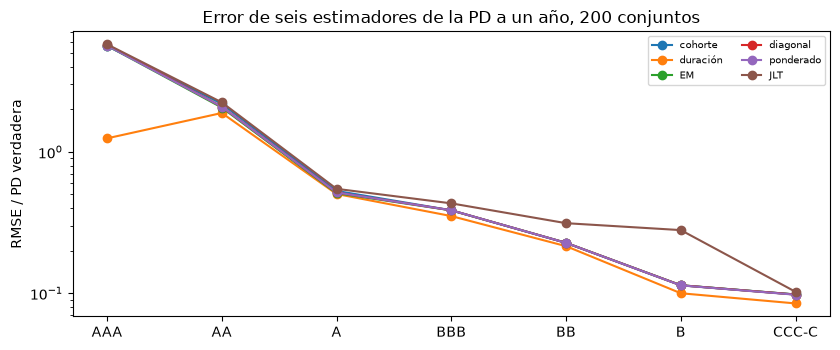

In [7]:
# Dibujar el RMSE relativo de los seis estimadores por grado
fig, ax = plt.subplots(figsize=(8.5, 3.6))
for key, label in names.items():
    ax.plot(range(7), np.array(study[key]["rmse"]) / truth, marker="o", label=label)
ax.set_yscale("log")
ax.set_xticks(range(7))
ax.set_xticklabels(grades)
ax.set_ylabel("RMSE / PD verdadera")
ax.set_title("Error de seis estimadores de la PD a un año, 200 conjuntos")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

## Resultados

- **Duración frente a cohorte, sobre una verdad conocida.** En los 200 conjuntos versionados el estimador de duración de AAA tiene un sesgo relativo de -0,06 (error Monte Carlo 0,09) y un RMSE relativo de 1,25; el estimador de cohorte tiene un sesgo de -0,44 y un RMSE de 5,61, y devuelve exactamente cero en el 99% de los conjuntos. De A a CCC-C los dos son cercanos (RMSE relativo 0,53 frente a 0,50 en A, 0,098 frente a 0,085 en CCC-C). El pequeño estudio con 60 simulaciones da el mismo orden, con el error que informa el arnés: para AAA un RMSE relativo de 1,40 (error estándar 0,14) para duración y 7,09 (3,5) para el estimador de cohorte.
- **EM y las reparaciones no agregan nada en el extremo delgado.** Los estimadores EM, diagonal y ponderado leen las mismas instantáneas anuales que el estimador de cohorte y tienen su error para AAA (RMSE relativo 5,63, 5,72 y 5,64) y un sesgo positivo de 0,5 a 0,6 ahí, porque nunca devuelven cero. JLT es peor desde BBB (RMSE relativo 0,43 frente a 0,39; 0,28 frente a 0,11 en B) con un sesgo de 0,19 a 0,25 en los grados medios.
- **Condicionamiento macro.** La tasa de incumplimiento especulativa promedia 3,75%; con una correlación supuesta de 12% los factores más bajos son 2009 (-1,72), 2002 (-1,42), 2001 (-1,35) y 2000 (-0,95), los más altos 2007 (1,15), 2006 (0,99), 2005 (0,85) y 2014 (0,70), y 14 de los 26 años son negativos. El producto lee este factor y prueba la estabilidad de la matriz; no ajusta una matriz condicionada.
- **En la matriz real los estimadores concuerdan donde hay datos.** PD a cinco años de CCC-C: 25,30% (matriz a la quinta), 25,15% (diagonal), 25,09% (ponderada), 25,27% (EM): una dispersión de 0,21 puntos; JLT da 26,18%, 0,92 puntos sobre EM. Para B la dispersión de los cuatro primeros es 0,04 puntos y JLT queda 0,85 sobre EM; para AAA los cuatro primeros quedan entre 0,103% y 0,127%.
- **La biblioteca de referencia.** La igualdad del estimador de cohorte con `transitionMatrix` es un test del motor (RV-415) que este cuaderno no vuelve a correr ni cuenta; la concordancia de arriba es la de los estimadores del producto entre sí.

Lo que este cuaderno no muestra: el efecto de la definición de incumplimiento y de los retiros sobre estas PD, ni la cobertura de los intervalos en grados delgados (cuaderno 10).

## Resumen

- El estimador de cohorte no puede ver la PD de AAA desde instantáneas anuales, ni EM ni las reparaciones de la matriz; el estimador de duración sí, donde hay trayectorias, con un error del orden de la PD misma.
- Donde hay datos los estimadores concuerdan en una fracción de punto a cinco años; JLT queda cerca de un punto sobre ellos.
- Los estimadores se comparan por sesgo y RMSE con sus errores Monte Carlo, sobre verdad conocida; un pequeño estudio con el arnés muestra cómo surgen los números.
- El producto lee el factor del ciclo crediticio y prueba la estabilidad de la matriz pero no ajusta ninguna matriz condicionada, y no corre ninguna reconciliación con una biblioteca de referencia.

**Qué probar después.** Sube las simulaciones del pequeño estudio a 200 y mira bajar los errores estándar; luego lee el cuaderno 09.

## Referencias

- ESMA, publicación CEREP de calificaciones y transiciones de agencias calificadoras. https://registers.esma.europa.eu/cerep-publication/
- Anderson, T. W. y Goodman, L. A. (1957), Statistical inference about Markov chains, Annals of Mathematical Statistics 28(1). https://doi.org/10.1214/aoms/1177707039
- Israel, R. B., Rosenthal, J. S. y Wei, J. Z. (2001), Finding generators for Markov chains via empirical transition matrices, Mathematical Finance 11(2). https://doi.org/10.1111/1467-9965.00114
- Schuermann, T. y Hanson, S. (2004), Estimating probabilities of default, FRBNY Staff Report 190. https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr190.pdf
- Brown, L. D., Cai, T. T. y DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- Lando, D. y Skodeberg, T. M. (2002), Analyzing rating transitions and rating drift with continuous observations, Journal of Banking and Finance 26(2-3), doi 10.1016/S0378-4266(01)00228-X.
- Belkin, B., Suchower, S. y Forest, L. R. (1998), A one-parameter representation of credit risk and transition matrices, CreditMetrics Monitor, tercer trimestre.
- Smith, A. y dos Reis, G. (2018), Quantitative Finance, doi 10.1080/14697688.2017.1383627, para el generador EM.
- Morris, T. P., White, I. R. y Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11), doi 10.1002/sim.8086.